# EDN compact peak pairs in Euclid DR1-Foundation
**Biswajit Jana** · 18 November 2026  
Independent research · Euclid Deep Field North

### Aim

Measure how often two close VIS peaks recur at the same sky positions in the NISP J image. Test whether the separation dependence persists among comparable VIS pairs, and measure how much of that pattern the J point-spread function and detection rule can produce on observed backgrounds. Examine EDN-004 for repeatable spectroscopic evidence about the two peaks.

The first six tile centres form the fixed pilot. The neighbouring twelve form the original held-out imaging sample. The matching, injection and expanded line tests were specified after inspecting that imaging result and should be treated as exploratory validation. All measurements use deterministic signal processing and conventional statistics.

In [1]:
import importlib.util
import io
import json
import os
from pathlib import Path
import subprocess
import sys
from zipfile import ZipFile

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MPLBACKEND", "Agg")

def run_python(*args):
    subprocess.run([sys.executable, *map(str, args)], check=True)

if any(importlib.util.find_spec(name) is None for name in ("astropy", "scipy", "pandas", "matplotlib")):
    run_python("-m", "pip", "install", "-q", "astropy>=7.2,<9", "numpy>=2",
               "scipy>=1.13", "pandas>=2", "matplotlib>=3.8")

slug = "edf-north-compact-doubles"
branch = "research/euclid-dr1-foundation-day01-20261114"
relative = Path("euclid-dr1-foundation") / slug
home = Path("/content") if Path("/content").is_dir() else Path.cwd()
bundle = home / "Euclid_DR1F_Reproducibility.zip"
explicit = os.environ.get("EUCLID_STUDY_ROOT")
if explicit:
    root = Path(explicit).resolve()
elif (home / slug / "validation_data").is_dir():
    root = home / slug
elif (home / "validation_data").is_dir():
    root = home
elif bundle.exists():
    with ZipFile(bundle) as z:
        selected = [n for n in z.namelist() if n.startswith(slug + "/")]
        if any(".." in Path(n).parts or Path(n).is_absolute() for n in selected):
            raise ValueError("Unsafe path in the input bundle")
        z.extractall(home, selected)
    root = home / slug
else:
    checkout = home / "euclid-edn"
    if not (checkout / ".git").exists():
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none",
                        "--sparse", "--branch", branch,
                        "https://github.com/Biswajit1999/daily-astro-notebooks.git",
                        str(checkout)], check=True)
    subprocess.run(["git", "-C", str(checkout), "sparse-checkout", "set",
                    str(relative)], check=True)
    root = checkout / relative
data = root / "validation_data"
results = root / "results"
assert (data / "observed_trials.npz").is_file(), "The local bundle or checkout needs the validation inputs"
sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import Image, Markdown, display
from matplotlib.ticker import PercentFormatter

def read_json(path):
    return json.loads(path.read_text())

def render(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=145, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

palette = {"pilot":"#247486", "holdout":"#a35033"}

## 1. Data and sample accounting

VIS and J are separate instruments aboard Euclid. The MER images share a 0.1 arcsec sampling grid. The experiment searches the central 6,144 × 6,144 samples of each tile. Acreage is computed from common finite, nonzero VIS and J pixels, with edges removed and disjoint WCS footprints verified.

The supplied candidate arrays are a compact copy of the 15,376 observed testable trials. Archives, original signed detections, masks and image products are recorded in the companion run bundle. An optional cell near the end reruns the original image detector from FITS ranges.

In [2]:
cohorts = read_json(results / "cohorts.json")
original = pd.DataFrame([
    dict(sample=k, tiles=len(v["coverage"]), optical_candidates=v["vis_kept_positive"],
         J_testable=v["j_tested"], J_repeat=v["j_repeat"],
         J_recovery_pct=100*v["j_repeat"]/v["j_tested"],
         shifted_testable=v["shift_tested"], shifted_repeat=v["shift_repeat"])
    for k, v in cohorts.items() if k in palette
])
display(original.round(2))
total = cohorts["total"]
assert not total["overlapping_tile_pairs"]
print(f'{total["paired_tiles"]} paired tiles; {total["nonoverlapping_common_area_deg2"]:.6f} deg² '
      f'of common coverage; {total["fits_image_range_bytes"]/1e9:.3f} GB of FITS row ranges')

18 paired tiles; 0.502917 deg² of common coverage; 9.024 GB of FITS row ranges


,sample,tiles,optical_candidates,J_testable,J_repeat,J_recovery_pct,shifted_testable,shifted_repeat
0,pilot,6,5495,5314,658,12.38,5309,0
1,holdout,12,10438,10062,1135,11.28,10075,0


In [3]:
from matched_recovery import COHORTS, SCORE_EDGES, RATIO_EDGES, study as match_study

with np.load(data / "observed_trials.npz", allow_pickle=False) as f:
    observed = pd.DataFrame(dict(f))
assert set(observed["passed"]) == {0, 1}
for i, name in enumerate(COHORTS):
    subset = observed[observed["cohort"] == i]
    assert len(subset) == cohorts[name]["j_tested"]
    assert int(subset["passed"].sum()) == cohorts[name]["j_repeat"]
display(observed.groupby("cohort").agg(testable=("passed","size"), repeats=("passed","sum"),
                                      median_weaker_VIS_score=("score","median")))

,testable,repeats,median_weaker_VIS_score
cohort,,,
0,5314,658,9.965565
1,10062,1135,10.027838


## 2. Compare at matched VIS peak strength and contrast

Does the wide-minus-narrow recovery difference survive matching? Compare the 0.38–0.50″ and 0.86–0.95″ bins. Group candidates by tile, weaker VIS peak score, and filtered amplitude ratio. Retain strata with both separation bins. The stratum weight is $n_\mathrm{narrow} n_\mathrm{wide}/(n_\mathrm{narrow}+n_\mathrm{wide})$. The two proportions use the same strata and weights.

A 10,000-draw whole-tile bootstrap gives descriptive intervals within each cohort. Adjacent tiles and shared processing can still share systematics. Vary the score and ratio binning and leave each tile out in turn to check sensitivity. The estimand is the recurrence difference over the common support of the measured scores.

In [4]:
matched = match_study(data / "observed_trials.npz")
frozen = read_json(data / "matched_recovery.json")
assert np.isclose(matched["holdout"]["primary"]["adjusted_difference"],
                  frozen["holdout"]["primary"]["adjusted_difference"])
rows = []
for name in COHORTS:
    for method, value in matched[name].items():
        low, high = 100*np.array(value["tile_bootstrap_95"])
        rows.append(dict(sample=name, method=method, strata=value["overlap_strata"],
                         narrow_pct=100*value["narrow"]["adjusted"],
                         wide_pct=100*value["wide"]["adjusted"],
                         difference_pp=100*value["adjusted_difference"], lower=low, upper=high,
                         narrow_supported=value["narrow"]["supported"],
                         wide_supported=value["wide"]["supported"]))
matched_table = pd.DataFrame(rows)
display(matched_table.round(2))

,sample,method,strata,narrow_pct,wide_pct,difference_pp,lower,upper,narrow_supported,wide_supported
0,pilot,primary,117,0.94,24.93,23.99,21.79,26.04,755,1003
1,pilot,coarser,34,0.95,26.22,25.28,23.74,27.17,760,1043
2,pilot,tile_only,6,1.05,24.29,23.25,20.68,26.94,760,1071
3,holdout,primary,231,0.66,22.71,22.05,20.03,24.04,1472,1974
4,holdout,coarser,70,0.68,23.63,22.95,21.46,24.44,1498,2022
5,holdout,tile_only,12,0.66,21.34,20.68,19.23,22.02,1498,2032


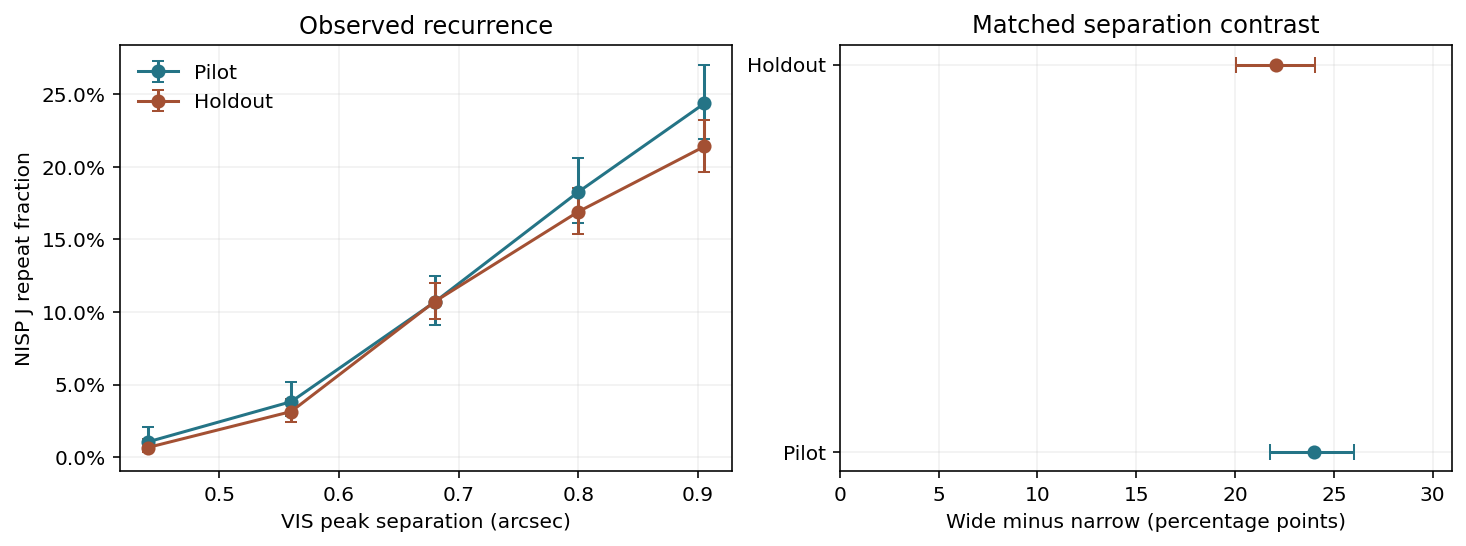

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.65), layout="constrained")
for name, color in palette.items():
    b = cohorts[name]["bins"]
    x = np.array([(r["lo"] + r["hi"])/2 for r in b])
    y = np.array([r["repeat"]/r["tested"] for r in b])
    intervals = np.asarray([r["wilson95"] for r in b]).T
    axes[0].errorbar(x, y, yerr=[y-intervals[0], intervals[1]-y], marker="o",
                     capsize=3, color=color, label=name.capitalize())
    value = matched[name]["primary"]
    effect = 100*value["adjusted_difference"]
    lo, hi = 100*np.array(value["tile_bootstrap_95"])
    axes[1].errorbar(effect, name.title(), xerr=[[effect-lo], [hi-effect]],
                     marker="o", capsize=4, color=color)
axes[0].set(xlabel="VIS peak separation (arcsec)", ylabel="NISP J repeat fraction",
            title="Observed recurrence")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(frameon=False)
axes[1].set(xlabel="Wide minus narrow (percentage points)", xlim=(0, 31),
            title="Matched separation contrast")
for ax in axes:
    ax.grid(alpha=.18)
render(fig)

In [6]:
for name in COHORTS:
    value = matched[name]["primary"]
    low, high = 100*np.array(value["leave_one_tile_out_range"])
    differences = np.array(list(value["individual_tile_difference"].values()), dtype=float)
    print(f'{name.title()}  {low:.1f}–{high:.1f} pp leaving one tile out; '
          f'{int(np.sum(differences > 0))}/{len(differences)} tile contrasts positive')
shifts = pd.read_json(results / "offset_controls.json").T
shifts.index.name = "bearing_deg"
display(shifts[["testable", "shifted_repeats", "paired_on_target_repeats"]])
print("Pilot offset repeats / placements", shifts["shifted_repeats"].sum(), "/", shifts["testable"].sum())

Pilot  23.2–24.7 pp leaving one tile out; 6/6 tile contrasts positive
Holdout  21.4–22.6 pp leaving one tile out; 12/12 tile contrasts positive
Pilot offset repeats / placements 1 / 42494


,testable,shifted_repeats,paired_on_target_repeats
bearing_deg,,,
0,5309,0,652
45,5308,1,649
90,5315,0,652
135,5320,0,653
180,5314,0,656
225,5313,0,654
270,5313,0,654
315,5302,0,650


## 3. What the J point-spread function does to a pair

The empirical profiles come from 298 Gaia DR3 stars measured on the released J mosaics. We required sensible Gaia astrometry, a compact isolated peak at the proper-motion-corrected position, and a strong measured J core. Each 25 × 25 cutout was recentered and normalized before the per-tile median stack. The FWHM numbers below describe fitted Gaussian core widths. The injections use the median empirical profiles, including their measured shape.

,tile,stars,median_core_FWHM_arcsec,blank_stamps
0,101829775,46,0.5024,6
1,101829777,47,0.5004,6
2,101829779,48,0.5050,6
3,101830399,39,0.5012,6
4,101830403,55,0.5030,6
5,101830407,63,0.5057,6


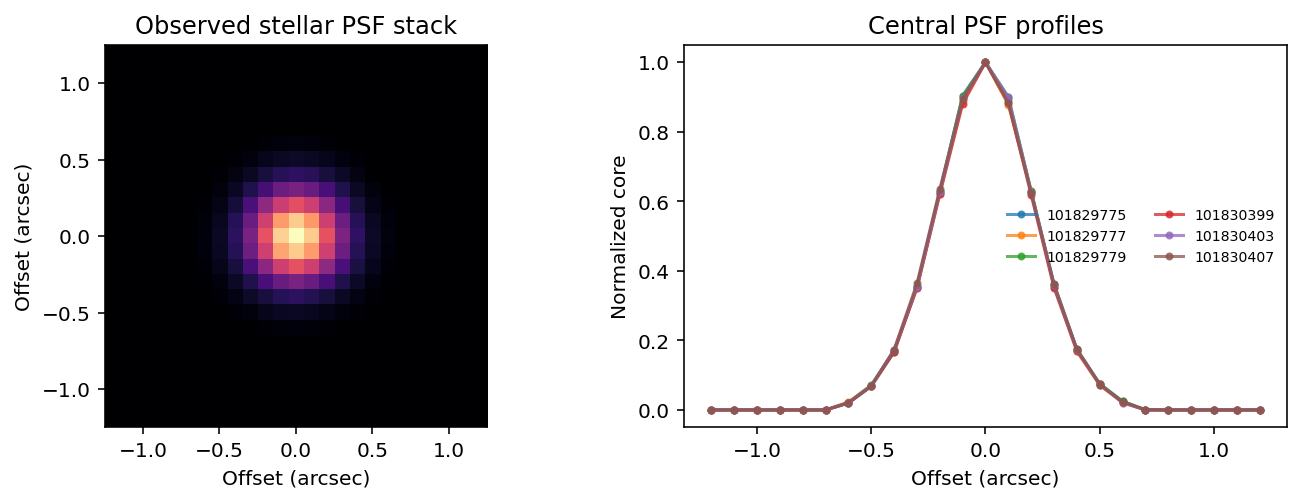

In [7]:
provenance = read_json(data / "injection_provenance.json")
display(pd.DataFrame([dict(tile=r["tile"], stars=len(r["stars"]),
                           median_core_FWHM_arcsec=r["median_fwhm_arcsec"],
                           blank_stamps=len(r["background_xy"])) for r in provenance]).round(4))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.35), layout="constrained")
with np.load(data / f'background_{provenance[0]["tile"]}.npz', allow_pickle=False) as f:
    first = f["profile"]
axes[0].imshow(first, extent=(-1.25,1.25,-1.25,1.25), origin="lower", cmap="magma")
axes[0].set(title="Observed stellar PSF stack", xlabel="Offset (arcsec)", ylabel="Offset (arcsec)")
for row in provenance:
    with np.load(data / f'background_{row["tile"]}.npz', allow_pickle=False) as f:
        profile = f["profile"]
    line = profile[12]
    axes[1].plot((np.arange(len(line))-12)*.1, line/line.max(), marker=".", alpha=.75,
                 label=str(row["tile"]))
axes[1].set(xlabel="Offset (arcsec)", ylabel="Normalized core", title="Central PSF profiles")
axes[1].legend(ncols=2, frameon=False, fontsize=7)
render(fig)

## 4. Inject two point sources into real J backgrounds

Place controlled pairs into 36 quiet J stamps, six per tile. Use separations from 0.40 to 0.90″, three random subpixel phases and orientations per stamp, two amplitude ratios, three isolated faint-component strengths and three PSF width scales. The original J rule is applied to each placement at the injected positions. An empty stamp and a single source supply matched controls at the nominal PSF scale.

The faint-component level is its isolated difference-of-Gaussians peak in units of the local filtered MAD scale. The noise comes from the observed stamp. Source shot noise, galaxy morphology, colour differences and VIS selection are outside this controlled experiment. The trials reuse backgrounds, so trial counts are descriptive.

In [8]:
from inject_pairs import run as inject_run, summarize as inject_summary

# True reruns the experiment on the supplied observed sky stamps.
RUN_INJECTIONS = True
if RUN_INJECTIONS:
    trials = inject_run(data, workers=3)
else:
    with np.load(data / "injection_trials.npz", allow_pickle=False) as f:
        trials = f["trials"]
injected = inject_summary(trials)
recorded = read_json(data / "injection_summary.json")
if injected != recorded:
    print("This run differs from the archived injection counts. Check the table below and the package versions.")
display(pd.DataFrame(injected["totals"]).T)

,tested,passed
double,11664,6587
single,648,0
empty,648,0


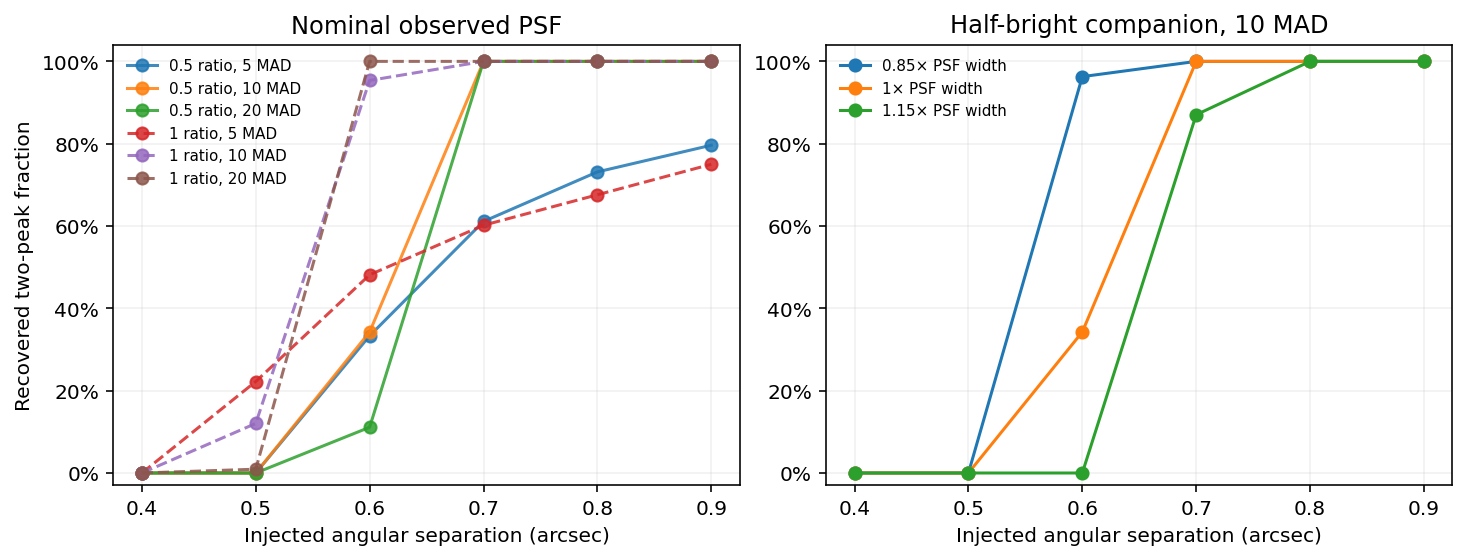

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.75), layout="constrained")
nominal = pd.DataFrame(injected["baseline"])
for (ratio, level), s in nominal.groupby(["ratio","faint_level"]):
    axes[0].plot(s["sep"], s["passed"]/s["tested"], marker="o",
                 alpha=.85, linestyle="-" if ratio == .5 else "--",
                 label=f'{ratio:g} ratio, {level:g} MAD')
sensitivity = pd.DataFrame(injected["width_sensitivity"])
for scale, s in sensitivity.groupby("width_scale"):
    axes[1].plot(s["sep"], s["passed"]/s["tested"], marker="o", label=f'{scale:g}× PSF width')
for ax, title in zip(axes, ["Nominal observed PSF", "Half-bright companion, 10 MAD"], strict=True):
    ax.set(title=title, xlabel="Injected angular separation (arcsec)", ylim=(-.03,1.04))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(alpha=.18)
    ax.legend(frameon=False, fontsize=7.5)
axes[0].set_ylabel("Recovered two-peak fraction")
render(fig)

In [10]:
scenario = nominal[(nominal["ratio"] == .5) & (nominal["faint_level"] == 10)]
display(scenario[["sep","passed","tested"]].assign(percent=lambda x:100*x.passed/x.tested).round(1))
display(sensitivity[np.isclose(sensitivity["sep"], .60)].round(3))

,sep,passed,tested,percent
2,0.4,0,108,0.0
8,0.5,0,108,0.0
14,0.6,37,108,34.3
20,0.7,108,108,100.0
26,0.8,108,108,100.0
32,0.9,108,108,100.0


,sep,width_scale,tested,passed
6,0.6,0.85,108,104
7,0.6,1.00,108,37
8,0.6,1.15,108,0


## 5. EDN-004 on the sky

The figure uses registered observed FITS planes. Gold ticks mark the VIS coordinates of the two peaks. The comparison from independently observed Subaru HSC i2 is resampled by MER. The apertures and component catalogue measurements are affected by blending.

EDN-004  RA 271.885434°, Dec +64.284832°, separation 0.949″
Axis dip by band {'VIS': '66.7%', 'J': '36.6%', 'HSC_I2': '22.9%'}


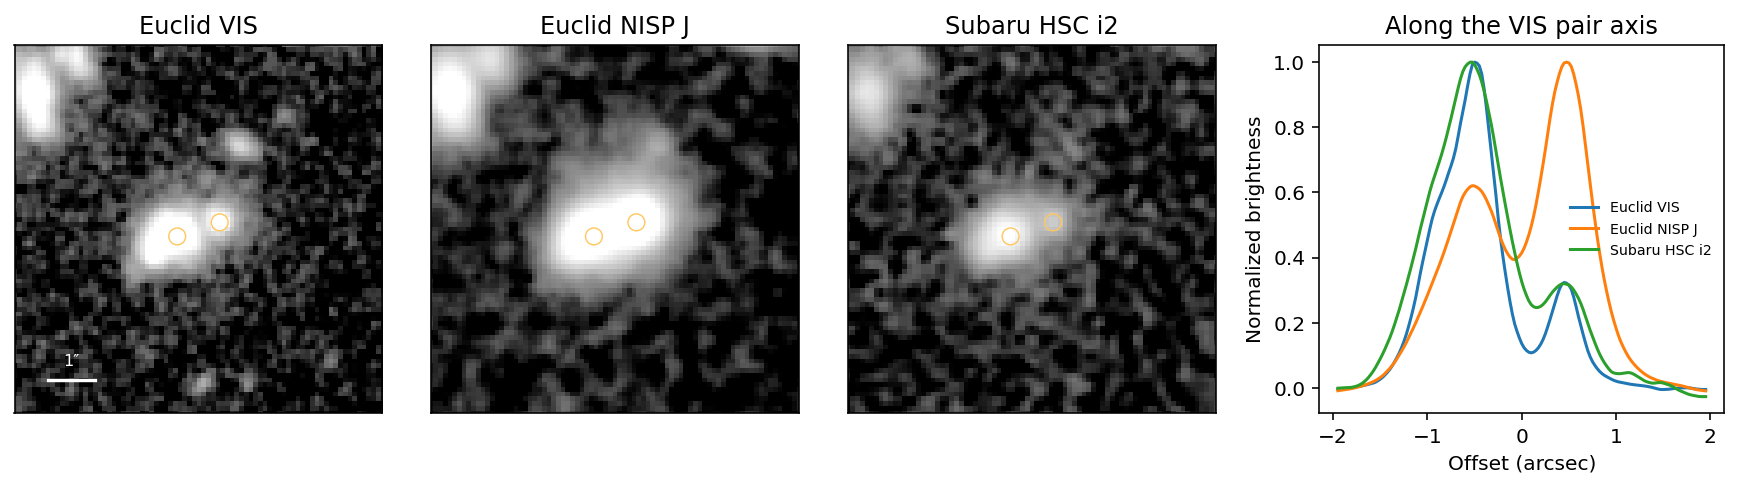

In [11]:
from image_checks import profile as axis_profile, peaks as profile_peaks

target = read_json(results / "audit.json")["EDN-004"]["candidate"]
stamp_path = results / "audit" / "EDN-004" / "registered.fits.gz"
fig, axes = plt.subplots(1, 4, figsize=(12, 3.25), layout="constrained")
offsets = np.arange(-1.95, 1.951, .025)
measured_dips = {}
with fits.open(stamp_path) as planes:
    wcs = WCS(planes["VIS"].header).celestial
    x, y = wcs.world_to_pixel_values([target["ra1"],target["ra2"]],[target["dec1"],target["dec2"]])
    for index, (band, label) in enumerate([("VIS","Euclid VIS"),("J","Euclid NISP J"),("HSC_I2","Subaru HSC i2")]):
        image = planes[band].data
        med = np.median(image)
        scale = 1.4826*np.median(np.abs(image-med))
        scaled = np.arcsinh((image-med)/scale)
        axes[index].imshow(scaled, origin="lower", interpolation="nearest", cmap="gray", vmin=-.5, vmax=4.5)
        axes[index].scatter(x, y, facecolors="none", edgecolors="#ffc75e", s=70, linewidths=.7)
        axes[index].set(title=label, xlim=(41,119), ylim=(41,119), xticks=[], yticks=[])
        line = axis_profile(image, x, y, offsets)
        measured_dips[band] = profile_peaks(line, offsets, float(target["sep_arcsec"])).get("dip")
        axes[-1].plot(offsets, line/line.max(), label=label)
axes[0].plot([48,58],[48,48],color="white",lw=1.7)
axes[0].text(53,51,'1″',color="white",ha="center",fontsize=8)
axes[-1].set(title="Along the VIS pair axis", xlabel="Offset (arcsec)", ylabel="Normalized brightness")
axes[-1].legend(frameon=False, fontsize=7)
render(fig)
print(f'EDN-004  RA {target["ra"]:.6f}°, Dec {target["dec"]:+.6f}°, separation {target["sep_arcsec"]:.3f}″')
print("Axis dip by band", {k: f"{100*v:.1f}%" for k,v in measured_dips.items() if v is not None})

## 6. Recheck the 1.31555 µm feature

The source of the test wavelength is the original blue feature and pipeline redshift proposal. Fit an inverse-variance local continuum and Gaussian at this fixed wavelength with line widths of 12, 16 and 24 Å. Use zero-mask pixels, at least four clean central bins and twelve sideband bins. A second run removes the highest signal-to-error central pixel. The per-dither values are formal diagnostics subject to spectral noise correlations and slitless overlap.

In [12]:
from edn004_recheck import TARGET_IDS, load_traces, summarize as refit_spectra

spectral = refit_spectra(data)
archived = read_json(data / "edn004_recheck.json")
assert len(spectral["exposures"]) == len(archived["exposures"]) == 80
for actual, expected in zip(spectral["exposures"], archived["exposures"], strict=True):
    assert actual["hdu"] == expected["hdu"] and actual["grism"] == expected["grism"]
    for new, old in zip(actual["fits"], expected["fits"], strict=True):
        for version in ("full", "clip"):
            assert new[version]["state"] == old[version]["state"]
            if "snr" in new[version]:
                assert np.isclose(new[version]["snr"], old[version]["snr"], rtol=1e-6, atol=1e-8)
exp_rows = []
for exp in spectral["exposures"]:
    for fit in exp["fits"]:
        exp_rows.append(dict(component="A" if int(exp["source"]) == TARGET_IDS[0] else "B",
                             grism=exp["grism"], hdu=exp["hdu"], orientation=exp["orientation"],
                             coadd=exp["coadd"], width_A=fit["width_A"],
                             full_snr=fit["full"].get("snr"), clipped_snr=fit["clip"].get("snr")))
exposure = pd.DataFrame(exp_rows)
coadds = exposure[exposure["coadd"]]
display(coadds[["component","grism","width_A","full_snr","clipped_snr"]].round(2))
dithers = exposure[~exposure["coadd"]].assign(full_pass=lambda x:x.full_snr.ge(4),
                                           clipped_pass=lambda x:x.clipped_snr.ge(4))
orientation = dithers.groupby(["component","orientation","width_A"]).agg(
    exposures=("hdu","size"), usable=("full_snr","count"), above_4=("full_pass","sum"),
    after_clip=("clipped_pass","sum")).reset_index()
display(orientation[(orientation["width_A"] == 16) | (orientation["orientation"] == "RGS180")])

,component,grism,width_A,full_snr,clipped_snr
0,B,BGS,12.0,0.02,-0.16
1,B,BGS,16.0,0.29,-0.06
2,B,BGS,24.0,0.88,0.42
27,A,BGS,12.0,7.69,5.92
28,A,BGS,16.0,9.58,7.84
29,A,BGS,24.0,9.57,7.89
54,B,RGS,12.0,NaN,NaN
55,B,RGS,16.0,NaN,NaN
56,B,RGS,24.0,NaN,NaN
147,A,RGS,12.0,NaN,NaN


,component,orientation,width_A,exposures,usable,above_4,after_clip
1,A,BGS000,16.0,8,6,2,2
4,A,RGS000,16.0,16,8,5,0
6,A,RGS180,12.0,14,1,1,1
7,A,RGS180,16.0,14,1,1,1
8,A,RGS180,24.0,14,1,1,0
10,B,BGS000,16.0,8,6,0,0
13,B,RGS000,16.0,16,7,0,0
15,B,RGS180,12.0,14,3,0,0
16,B,RGS180,16.0,14,3,0,0
17,B,RGS180,24.0,14,3,0,0


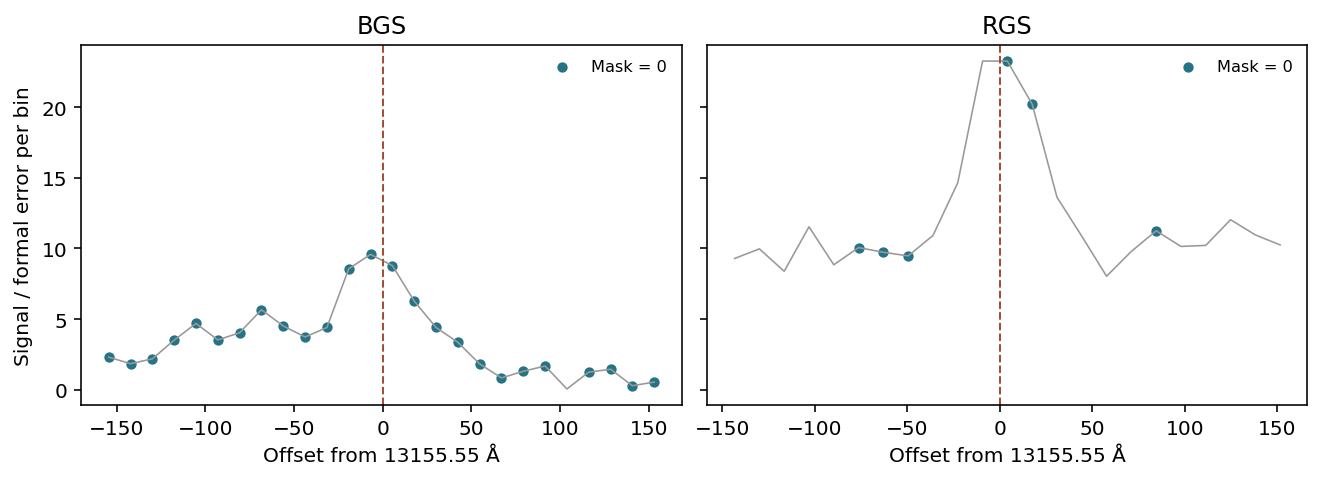

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True, layout="constrained")
for ax, grism in zip(axes, ("BGS","RGS"), strict=True):
    for source, band, hdu, _, values in load_traces(data):
        if source != TARGET_IDS[0] or band != grism or "_COMBINED" not in hdu:
            continue
        w, f, v, m = values.T
        x = w-spectral["source_line_A"]
        selection = (np.abs(x) <= 155) & np.isfinite(f) & (v > 0)
        clean = selection & (m == 0)
        ax.plot(x[selection], f[selection]/np.sqrt(v[selection]), color=".6", lw=.8)
        ax.scatter(x[clean], f[clean]/np.sqrt(v[clean]), color="#247486", s=17, label="Mask = 0")
    ax.axvline(0, ls="--", color="#a35033", lw=1.)
    ax.set(title=grism, xlabel="Offset from 13155.55 Å")
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("Signal / formal error per bin")
render(fig)

In [14]:
hypotheses = pd.DataFrame([
    dict(assumed_feature=row["hypothesis"], redshift=row["z"], grism=row["grism"],
         companion_line=row["line"], wavelength_A=row["full"]["center_A"],
         clean_core=row["full"]["core_bins"], clean_sideband=row["full"]["sideband_bins"],
         formal_SNR=row["full"].get("snr"))
    for row in spectral["alternative_lines"]
])
display(hypotheses[hypotheses["formal_SNR"].notna()].round(3))
print(f'{hypotheses.formal_SNR.notna().sum()}/{len(hypotheses)} diagnostic windows meet clean-coverage cuts.')
print(f'Largest positive follow-up-line S/N   {hypotheses.formal_SNR.max():.2f}')

3/22 diagnostic windows meet clean-coverage cuts.
Largest positive follow-up-line S/N   1.89


,assumed_feature,redshift,grism,companion_line,wavelength_A,clean_core,clean_sideband,formal_SNR
2,Halpha,1.004,BGS,[S II] 6718,13463.522,6,12,1.890
4,[O III] 5008,1.627,BGS,[O III] 4960,13029.618,5,12,-1.122
5,[O III] 5008,1.627,BGS,Hbeta,12773.192,6,14,-0.607


## 7. What we found

- Recovery at the same J positions depends strongly on VIS separation. In the held-out cohort, the matched wide-minus-narrow difference is **22.0 percentage points** (whole-tile interval **20.0–24.0 points**).
- With the measured J profile, a half-bright companion at an isolated strength of 10 local MAD units was recovered **37/108** times at 0.60″ and **108/108** at 0.70″. At 0.60″, recovery changes from **104/108** to **0/108** between the narrower and broader PSF sensitivity settings. The J response and the peak rule alone produce a steep separation dependence in this experiment.
- EDN-004 has a repeatable feature in one extraction. After removing the strongest bin, two blue dithers still pass formal S/N 4 across all three tested widths. The red 180-degree exposure passes at 12 and 16 Å. The other component has no equivalent repeat under these cuts. The follow-up line windows supply no second positive detection at S/N 4. Its line identity and the connection between the peaks remain open.

The sample spans **0.503 deg²** in one field. The injection curves describe compact point sources at the tested strengths. Estimating the abundance of physical pairs would require a survey selection function and reliable component classifications.

## 8. Optional archive replay

The default workflow above runs from observed tabular measurements, observed background and PSF stamps, registered FITS cutouts, and released spectrum samples. Use this cell to rerun the original detector on selected tile IDs. Each complete centre uses about 0.50 GB of FITS row ranges across both bands. Select a short batch for Colab and download its output before the runtime resets.

In [15]:
RUN_ARCHIVE_REPLAY = False
replay_tiles = [101829781, 101829782]
cache = home / "euclid-archive-cache"
replay_output = home / "euclid-archive-replay"
if RUN_ARCHIVE_REPLAY:
    run_python(root / "search_doubles.py", "--cache", cache, "--output", replay_output,
               "--workers", 2, "--tiles", *replay_tiles)
    replay = read_json(replay_output / "search_summary.json")
    missing = [r["tile"] for r in replay["tiles"] if "vis" not in r or "j" not in r]
    print("Missing paired products", missing)
    print("Repeats / testable", replay["j_repeat"], "/", replay["j_tested"])
else:
    print("Set RUN_ARCHIVE_REPLAY = True to repeat the FITS image search.")

Set RUN_ARCHIVE_REPLAY = True to repeat the FITS image search.


## References and credits

Research author **Biswajit Jana**. Imaging data from ESA, Euclid, the Euclid Consortium and NASA, distributed by IRSA. External images from Subaru WISHES. Gaia DR3 point-source data accessed through IRSA.

- [Aussel et al. 2026, Euclid DR1 overview](https://arxiv.org/abs/2611.16510)
- [McCracken et al. 2026, VIS processing](https://arxiv.org/abs/2611.15890)
- [Polenta et al. 2026, NIR processing](https://arxiv.org/abs/2611.16119)
- [Da Silva et al. 2026, NISP PSF modelling](https://arxiv.org/abs/2611.16494)
- [Fumana et al. 2026, SIR spectroscopic calibration](https://arxiv.org/abs/2611.17305)
- [IRSA MER archive tutorial](https://caltech-ipac.github.io/irsa-tutorials/euclid-cloud-access/)